# The page under attack from three roles, with gaming and the seven lines: does each line resist the gaming it must, and does the page answer all three roles?

**Week 4, Monday, chapter 10 of 11, the fourth case chapter.** It applies two of the morning's
topics: *Gaming, and definitions that resist it*, taught in
`C2_W04_D01_05_gaming_resistant_definitions_STUDENT.ipynb`, and *The metric definition
artifact*, taught in `C2_W04_D01_06_metric_definition_artifact_STUDENT.ipynb`. Level 5 of the
case's six: decide, cost the decision and defend it against the people it costs. Round 3 of
the war game runs beside it.

**The case.** Uber's Hyderabad city team launched a peak-hour earnings guarantee on Monday
31 August 2026: a floor of Rs 300 per peak online hour, with Uber paying the gap between a
driver's trip earnings and the floor as a top-up. Six weeks on, peak online hours are up 24
percent and completed peak trips 3 percent.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

Notebook 09 wrote the redesign's seven-line page and found Rs 1.159 crore of the top-up paid to
driver-weeks that accepted fewer than half their offers. This notebook puts the page under
attack, first from each way of gaming the scheme, then from the three people in the room who
each lose something under it, and prices what the redesign would save. Two floors run through
it: the Rs 300 floor is what a driver-week is guaranteed, and the acceptance floor is the share
of offers a driver-week must accept to earn it.

**Who needs the answer.** The city head, who signs the page on Friday, and the three people
who each lose something under it: the driver-operations lead, the marketing lead and the
finance partner. A page that cannot answer them is dropped, and the city keeps paying for
hours.

**The questions on the way.**

1. Does the redesign's page hold all seven lines?
2. Does each line resist the gaming it must?
3. Driver operations: if drivers log off, what would riders lose, and which line shows it?
4. Marketing: does the Rs 300 floor stay for every driver who serves riders?
5. Finance: is the fall the monsoon's end?
6. What would the redesign save, under a stated assumption about how drivers respond?
7. Where does the acceptance floor sit if an accepted trip later cancelled counts as declined?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
zw = pd.read_csv("../data/C2_W04_D01_zone_weeks_STUDENT.csv")
dw["window"] = dw["week_start"].lt("2026-08-31").map({True: "before", False: "after"})
after = dw[dw["window"] == "after"]
per_driver = after.groupby("driver_id")[["peak_trips", "peak_online_hours"]].sum()
idle = set(per_driver.index[per_driver["peak_trips"] / per_driver["peak_online_hours"] < 1.0])

def group(driver_id):
    """The idle tail, the 140 who joined after the launch (ids above d_1060), or the other 880."""
    if driver_id in idle:
        return "idle tail"
    return "joined after the launch" if driver_id > "d_1060" else "the other 880"

dw["group"] = dw["driver_id"].map(group)
on_after = dw[(dw["window"] == "after") & (dw["peak_online_hours"] > 0)]
print(f"{len(idle)} drivers in the idle tail, found as notebook 08 found them; "
      f"{len(on_after):,} driver-weeks online after the launch")

180 drivers in the idle tail, found as notebook 08 found them; 6,434 driver-weeks online after the launch


## Does the redesign's page hold all seven lines?

This cell writes notebook 09's page as a seven-key dictionary, the shape chapter 6 used for
Balaji Kirana (invented), and runs chapter 6's check, `missing_lines(page)`, copied here from
notebook 06 so this notebook stands alone. The check lists every blank line and every
guardrail the gaming note does not say it catches.

In [2]:
LINES = ["numerator", "denominator", "window", "exclusions", "does_not_reward", "guardrails", "gaming_note"]

def written(value):
    """A line counts as written when it holds something other than the ____ placeholder."""
    return bool(value) and "____" not in str(value)

def missing_lines(page):
    """The page's blank lines, then every guardrail its gaming note does not say it catches."""
    blank_lines = [line for line in LINES if not written(page.get(line))]
    note = page.get("gaming_note") or {}
    unnamed = [g for g in page.get("guardrails") or [] if not written(note.get(g))]
    return blank_lines + [f"a guardrail that catches nothing named: {g}" for g in unnamed]

uber = {"numerator": "trips completed inside the peak windows, one per paying rider",
        "denominator": "enrolled drivers online at least one peak hour that week, the count printed beside the rate",
        "window": "the calendar week",
        "exclusions": "trips cancelled by either side, test accounts, trips outside the windows",
        "does_not_reward": "hours online, offers declined, a shrinking enrolled base",
        "guardrails": ["offers accepted over offers shown, at or above an acceptance floor",
                       "median rider wait at peak, by zone", "top-up per completed trip"],
        "gaming_note": {"offers accepted over offers shown, at or above an acceptance floor": "catches declining and cherry-picking",
                        "median rider wait at peak, by zone": "catches supply that stops serving riders",
                        "top-up per completed trip": "catches a top-up that runs away from the trips it pays for"}}

for line in LINES:
    value = uber[line]
    if isinstance(value, dict):
        value = "; ".join(f"{g} {what}" for g, what in value.items())
    elif isinstance(value, list):
        value = "; ".join(value)
    print(f"{line.replace('_', ' ')}: {value}")
print("missing:", missing_lines(uber) or "nothing")

numerator: trips completed inside the peak windows, one per paying rider
denominator: enrolled drivers online at least one peak hour that week, the count printed beside the rate
window: the calendar week
exclusions: trips cancelled by either side, test accounts, trips outside the windows
does not reward: hours online, offers declined, a shrinking enrolled base
guardrails: offers accepted over offers shown, at or above an acceptance floor; median rider wait at peak, by zone; top-up per completed trip
gaming note: offers accepted over offers shown, at or above an acceptance floor catches declining and cherry-picking; median rider wait at peak, by zone catches supply that stops serving riders; top-up per completed trip catches a top-up that runs away from the trips it pays for
missing: nothing


## Does each line resist the gaming it must?

Chapter 5 named the ways a number is gamed, and chapter 6 said a guardrail earns its place by
the gaming it catches. The page survives only if each way of gaming the scheme meets a line
that stops it. The redesign's north star is completed peak trips per enrolled driver online at
peak, per week: trips over the driver-weeks with at least one peak online hour.

**Predict before you run.** Suppose every idle-tail driver doubled the peak online hours of
every week after the launch, with the same trips. What would the north star read after the
launch?

a) 35.89, as it reads now.
b) Higher, about 41.
c) Lower, about 30.
d) Doubled, about 72.

This cell writes the north star as a function and reads it on the six weeks after the launch
three times: as the data stands, with the idle tail's hours doubled, and with the idle tail
logged off, its driver-weeks taken out.

In [3]:
def north_star(d):
    """Completed peak trips per driver-week with at least one peak online hour, and that count."""
    online = d[d["peak_online_hours"] > 0]
    return round(online["peak_trips"].sum() / len(online), 2), len(online)

in_idle = after["driver_id"].isin(idle)
doubled = after.assign(peak_online_hours=after["peak_online_hours"].where(~in_idle, 2 * after["peak_online_hours"]))
moves = pd.DataFrame([("as the data stands", *north_star(after)),
                      ("the idle tail doubles its hours", *north_star(doubled)),
                      ("the idle tail logs off", *north_star(after[~in_idle]))],
                     columns=["after the launch", "north_star", "online_driver_weeks"]).set_index("after the launch")
moves

,north_star,online_driver_weeks
after the launch,,
as the data stands,35.89,6434
the idle tail doubles its hours,35.89,6434
the idle tail logs off,36.88,5354


**What happened.** The answer is a. Doubling the idle tail's hours leaves the north star at
35.89, because hours sit in neither its numerator (trips) nor its denominator (drivers online
at least one peak hour): logging in for longer cannot raise it. Logging off can. With the idle
tail's 1,080 driver-weeks taken out, the north star rises to 36.88, although the 33,440 trips
those drivers made are gone unless other drivers carry them. That is why the page prints the
count beside the rate (6,434 driver-weeks against 5,354), says it does not reward a shrinking
base, and guards the riders' side with the wait.

This cell draws each way of gaming the scheme against the lines of the page, with a filled
square where a line stops the move. The last move is one the redesign itself invites: a driver
parked in a thin zone who accepts the few offers shown there clears the acceptance floor, and
only top-up per completed trip shows what that week cost. The redesign has not run, so the data
cannot show that move yet.

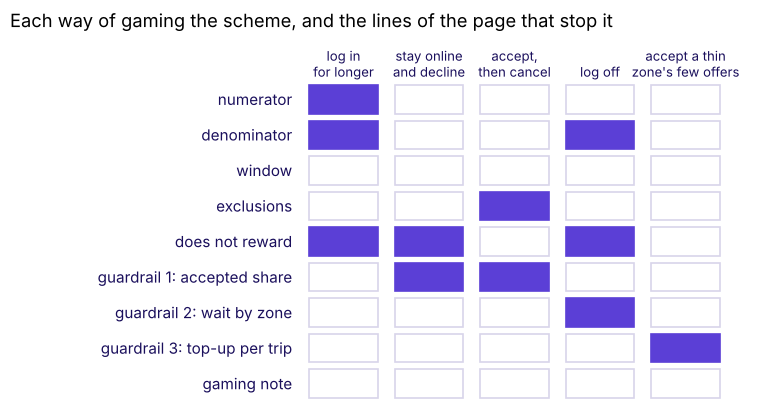

log in for longer is stopped by: numerator, denominator, does not reward
stay online and decline is stopped by: does not reward, guardrail 1: accepted share
accept, then cancel is stopped by: exclusions, guardrail 1: accepted share
log off is stopped by: denominator, does not reward, guardrail 2: wait by zone
accept a thin zone's few offers is stopped by: guardrail 3: top-up per trip


In [4]:
MOVES = ["log in\nfor longer", "stay online\nand decline", "accept,\nthen cancel", "log off",
         "accept a thin\nzone's few offers"]
ROWS = ["numerator", "denominator", "window", "exclusions", "does not reward", "guardrail 1: accepted share",
        "guardrail 2: wait by zone", "guardrail 3: top-up per trip", "gaming note"]
STOPS = {"numerator": [0], "denominator": [0, 3], "exclusions": [2], "does not reward": [0, 1, 3],
         "guardrail 1: accepted share": [1, 2], "guardrail 2: wait by zone": [3],
         "guardrail 3: top-up per trip": [4]}
fig, ax = plt.subplots(figsize=(9.6, 4.8))
for r, line in enumerate(ROWS):
    y = len(ROWS) - 1 - r
    ax.text(-0.6, y, line, ha="right", va="center", color=INK)
    for c in range(len(MOVES)):
        hit = c in STOPS.get(line, [])
        ax.add_patch(plt.Rectangle((c - 0.4, y - 0.4), 0.8, 0.8, fc=VIOLET if hit else "white",
                                   ec=VIOLET if hit else "#D8D4EA", lw=1.2))
for c, move in enumerate(MOVES):
    ax.text(c, len(ROWS) - 0.45, move, ha="center", va="bottom", color=INK, fontsize=9.5)
ax.set_xlim(-3.9, len(MOVES) - 0.2)
ax.set_ylim(-0.6, len(ROWS) + 0.8)
ax.axis("off")
ax.set_title("Each way of gaming the scheme, and the lines of the page that stop it", loc="left")
plt.show()
for c, move in enumerate(MOVES):
    print(move.replace("\n", " "), "is stopped by:", ", ".join(line for line, cols in STOPS.items() if c in cols))

**What happened.** Every move meets at least one line. The window and the gaming note stop no
move of their own: the window makes the number computable, and the gaming note records which
move each guardrail catches. Logging off is the one move the north star itself rewards, so the
page meets it three times: the count printed beside the rate, the line on what it does not
reward, and the wait.

## Driver operations: if drivers log off, what would riders lose, and which line shows it?

The driver-operations lead says drivers will log off once the acceptance floor asks that half
their offers be accepted. Part of that is true: the 180 drivers of the idle tail may well log off. The rest
is a question the data can answer: did the drivers who serve riders change how they drove?

This cell sums hours and trips by window for the idle tail and for the other 880 who joined
before the launch, leaving out the 140 who joined after it, and draws each group's weekly
trips per peak online hour.

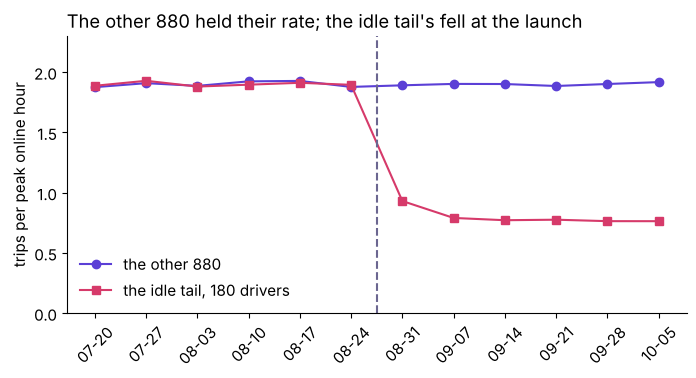

                      peak_online_hours  peak_trips  trips_per_hour
group         window                                               
the other 880 before              98000      186200             1.9
              after              102000      193800             1.9
idle tail     before              20000       38000             1.9
              after               42000       33440             0.8
if the idle tail logged off, its 33,440 trips would need about 17,600 more peak online hours at 1.90 trips an hour


In [5]:
both = dw[dw["group"] != "joined after the launch"]
groups = both.groupby(["group", "window"])[["peak_online_hours", "peak_trips"]].sum()
groups["trips_per_hour"] = (groups["peak_trips"] / groups["peak_online_hours"]).round(2)
groups = groups.loc[[("the other 880", "before"), ("the other 880", "after"), ("idle tail", "before"), ("idle tail", "after")]]
weekly = both.groupby(["week_start", "group"])[["peak_trips", "peak_online_hours"]].sum()
rate = (weekly["peak_trips"] / weekly["peak_online_hours"]).unstack()
fig, ax = plt.subplots(figsize=(8.0, 3.6))
ax.plot(range(12), rate["the other 880"], marker="o", color=VIOLET, label="the other 880")
ax.plot(range(12), rate["idle tail"], marker="s", color=ROSE, label="the idle tail, 180 drivers")
ax.axvline(5.5, color=MUTED, linestyle="--")
ax.set_xticks(range(12), [w[5:] for w in rate.index], rotation=45)
ax.set_ylim(0, 2.3)
ax.set_ylabel("trips per peak online hour")
ax.legend(frameon=False, loc="lower left")
ax.set_title("The other 880 held their rate; the idle tail's fell at the launch", loc="left")
plt.show()
idle_trips = groups.loc[("idle tail", "after"), "peak_trips"]
carry = int(round(idle_trips / 1.9))
print(groups)
print(f"if the idle tail logged off, its {idle_trips:,} trips would need about {carry:,} more peak online hours at 1.90 trips an hour")

**What happened.** The other 880 made 1.90 trips per peak online hour before the launch and
1.90 after: the drivers who serve riders did not change. The idle tail fell from 1.90 to 0.80.
If the idle tail logged off, its 33,440 trips would need about 17,600 more peak online hours
from the others at 1.90 trips an hour. Whether riders would then wait longer is what guardrail
2 answers: the median rider wait at peak, read zone by zone, moves for riders when supply that
served them leaves, while the north star, as the cell above showed, would rise. The line that
answers driver operations is guardrail 2, and the count printed beside the rate shows who left.

## Marketing: does the Rs 300 floor stay for every driver who serves riders?

The marketing lead says changing the terms looks like bait, since the Rs 300 floor was the
promise.
The redesign keeps the Rs 300 floor for every driver-week that accepts at least half its
offers, so the question for the data is how many driver-weeks outside the idle tail would lose
it.

**Predict before you run.** Of the driver-weeks online after the launch outside the idle tail,
how many accepted fewer than half their offers? a) none; b) about 100; c) about 1,000; d) about
2,000.

This cell draws each driver-week's accepted share after the launch, the idle tail against every
other driver-week, with the acceptance floor at 0.5.

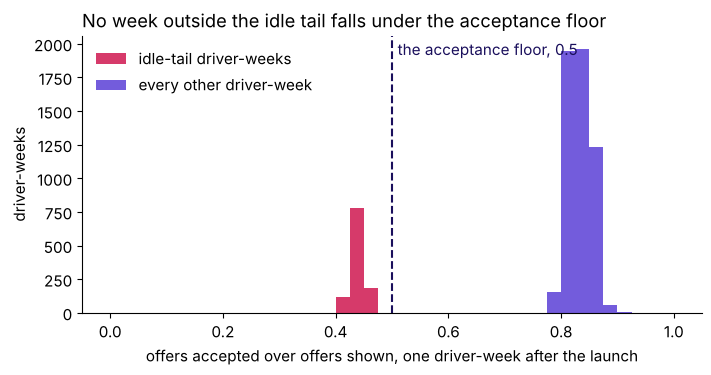

the idle tail's highest week accepted 0.46; every other week at least 0.78; driver-weeks outside the idle tail under 0.5: 0


In [6]:
share = on_after["peak_accepted"] / on_after["peak_offers"]
in_tail = on_after["driver_id"].isin(idle)
bins = [i / 40 for i in range(41)]
fig, ax = plt.subplots(figsize=(8.0, 3.6))
ax.hist(share[in_tail], bins=bins, color=ROSE, label="idle-tail driver-weeks")
ax.hist(share[~in_tail], bins=bins, color=VIOLET, alpha=0.85, label="every other driver-week")
ax.axvline(0.5, color=INK, linestyle="--")
ax.text(0.51, 0.93, "the acceptance floor, 0.5", color=INK, transform=ax.get_xaxis_transform())
ax.set_xlabel("offers accepted over offers shown, one driver-week after the launch")
ax.set_ylabel("driver-weeks")
ax.legend(frameon=False, loc="upper left")
ax.set_title("No week outside the idle tail falls under the acceptance floor", loc="left")
plt.show()
edges = (round(share[in_tail].max(), 2), round(share[~in_tail].min(), 2))
under = int((share[~in_tail] < 0.5).sum())
print(f"the idle tail's highest week accepted {edges[0]}; every other week at least {edges[1]}; "
      f"driver-weeks outside the idle tail under 0.5: {under}")

**What happened.** The answer is a: no driver-week outside the idle tail accepted fewer than
half its offers. The idle tail's highest week accepted 0.46 and every other week at least 0.78,
so an acceptance floor at 0.5 takes the top-up from idle-tail weeks only, and every driver who
serves riders keeps the promise. The gap is this clean because the data is synthetic; on a real
city the two groups overlap, and where the acceptance floor sits becomes a trade-off the test
measures. The line that answers marketing is guardrail 1's acceptance floor, written into the
payout rule.

## Finance: is the fall the monsoon's end?

The finance partner says the fall in trips per hour is the season, since the monsoon ended
inside the after window. Part of that is true: the season moves rider requests. The question is
whether the rate moved with requests or with the launch.

This cell draws the city's weekly rider requests beside its weekly trips per peak online hour.

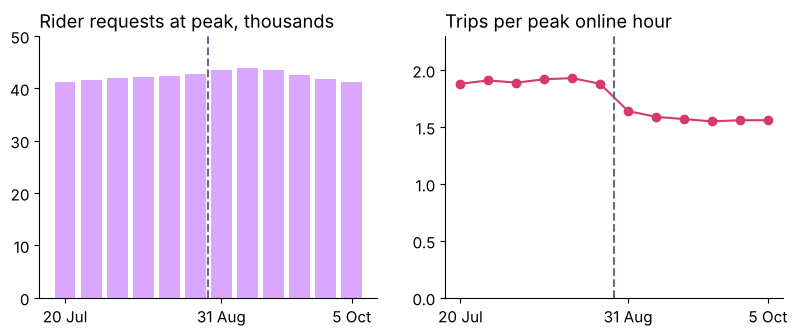

weekly requests from 41,155 to 43,878
trips per peak online hour, the week before the launch 1.88, the launch week 1.64
the three weeks with most requests (2026-09-07, 2026-08-31, 2026-09-14) read 1.60


In [7]:
weeks = dw.groupby("week_start")[["peak_trips", "peak_online_hours"]].sum()
weeks["trips_per_hour"] = (weeks["peak_trips"] / weeks["peak_online_hours"]).round(2)
weeks["requests"] = zw.groupby("week_start")["peak_requests"].sum()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.4))
a1.bar(range(12), weeks["requests"] / 1000, color=LAV)
a1.set_ylim(0, 50)
a1.set_title("Rider requests at peak, thousands", loc="left")
a2.plot(range(12), weeks["trips_per_hour"], marker="o", color=ROSE)
a2.set_ylim(0, 2.3)
a2.set_title("Trips per peak online hour", loc="left")
for a in (a1, a2):
    a.axvline(5.5, color=MUTED, linestyle="--")
    a.set_xticks([0, 6, 11], ["20 Jul", "31 Aug", "5 Oct"])
plt.show()
busiest = weeks["requests"].nlargest(3).index
crest = round(weeks.loc[busiest, "peak_trips"].sum() / weeks.loc[busiest, "peak_online_hours"].sum(), 2)
step = (weeks.loc["2026-08-24", "trips_per_hour"], weeks.loc["2026-08-31", "trips_per_hour"])
print(f"weekly requests from {weeks['requests'].min():,} to {weeks['requests'].max():,}")
print(f"trips per peak online hour, the week before the launch {step[0]:.2f}, the launch week {step[1]:.2f}")
print(f"the three weeks with most requests ({', '.join(busiest)}) read {crest:.2f}")

**What happened.** Weekly requests stayed between 41,155 and 43,878 across all twelve weeks,
while the rate stepped from 1.88 in the week before the launch to 1.64 in the launch week, and
the three weeks with the most requests, the first three after the launch and still in the
rains, read 1.60. The season moved requests within a narrow band; the rate fell in the week the
scheme began. The line that answers finance is the window: a calendar week shows the step that
six-week totals blur. The top-up budget is finance's own number, so finance watches guardrail 3,
top-up per completed trip, and decides what the Rs 300 floor may cost.

## What would the redesign save, under a stated assumption about how drivers respond?

The redesign keeps the Rs 300 floor only for driver-weeks that clear the acceptance floor of
half the offers shown. The weeks under half are the idle tail's, as the marketing cell showed:
its highest week accepted 0.46 and every other week at least 0.78. Some idle-tail drivers would
start accepting enough to qualify, so the share of their top-up that would still be paid is an
**assumption**: 0.2 at the low end, 0.5 at the high end. A test of the redesign, which this
afternoon's tentative faculty block designs, is what settles it. This cell splits the top-up at
half accepted, checks that the part under half is exactly the idle tail's, and prices both ends.

In [8]:
acc = after["peak_accepted"] / after["peak_offers"]
low = after.loc[acc < 0.5, "topup_rs"].sum()
high = after.loc[acc >= 0.5, "topup_rs"].sum()
idle_topup = after.loc[after["driver_id"].isin(idle), "topup_rs"].sum()
saving = pd.DataFrame({"still_paid_share": [0.2, 0.5]})
saving["saving_rs"] = (low * (1 - saving["still_paid_share"])).round().astype(int)
saving["saving_lakh"] = (saving["saving_rs"] / 1e5).round(1)
print(f"top-up to weeks under half: Rs {low:,}; to the rest: Rs {high:,}; the idle tail's own: Rs {idle_topup:,}")
saving

top-up to weeks under half: Rs 11,590,000; to the rest: Rs 7,410,000; the idle tail's own: Rs 11,590,000


,still_paid_share,saving_rs,saving_lakh
0,0.2,9272000,92.7
1,0.5,5795000,58.0


**What happened.** Rs 1.159 crore went to weeks under half, all of it the idle tail's, and
Rs 74 lakh to the rest. If a fifth of the idle tail's top-up were still paid, the redesign saves
Rs 92.7 lakh over six weeks; if half were, Rs 58.0 lakh. The range is the honest answer to
finance until the test reports, and Rs 74 lakh, what the other weeks received, is the least the
redesign would cost.

### Your turn: where does the acceptance floor sit if an accepted trip later cancelled counts as declined?

The payout rule counts an accepted trip that the driver later cancelled as declined, so a
driver cannot clear the acceptance floor by accepting and cancelling. In this data every accepted trip
either became a completed trip or was cancelled by the driver, so the rule's share is trips
completed over offers shown. Fill the two blanks, then type and run the lines in the empty
cell below:

```python
done = on_after["peak_trips"] / on_after["____"]
in_tail = on_after["driver_id"].isin(idle)
idle_edge = round(done[in_tail].max(), 2)
other_edge = round(done[~in_tail].____(), 2)
print(idle_edge, other_edge)
```

The check under it compares your two edges with the reference and asks whether 0.5 still sits
between them.

In [9]:
mine = (globals().get("idle_edge"), globals().get("other_edge"))
if None in mine:
    print("Store idle_edge and other_edge in the empty cell above, then run this cell again.")
else:
    done = on_after["peak_trips"] / on_after["peak_offers"]
    tail = on_after["driver_id"].isin(idle)
    reference = (round(done[tail].max(), 2), round(done[~tail].min(), 2))
    print("the reference edges:", reference)
    check("your edges match the reference, and 0.5 still sits between them",
          tuple(mine) == reference and reference[0] < 0.5 < reference[1])

Store idle_edge and other_edge in the empty cell above, then run this cell again.


This cell checks the claims the chapter makes about its own numbers.

In [10]:
check("the redesign's page holds all seven lines", missing_lines(uber) == [])
check("doubling the idle tail's hours leaves the north star at 35.89",
      moves["north_star"].tolist()[:2] == [35.89, 35.89])
check("the idle tail logging off raises the north star to 36.88, on 5,354 driver-weeks against 6,434",
      moves.loc["the idle tail logs off"].tolist() == [36.88, 5354]
      and moves.loc["as the data stands", "online_driver_weeks"] == 6434)
check("every way of gaming the scheme meets a line that stops it",
      all(any(c in cols for cols in STOPS.values()) for c in range(len(MOVES))))
check("the other 880 held 1.90 trips an hour in both windows; the idle tail fell from 1.90 to 0.80",
      groups["trips_per_hour"].tolist() == [1.9, 1.9, 1.9, 0.8])
check("the idle tail's 33,440 trips would need about 17,600 hours at 1.90", (idle_trips, carry) == (33440, 17600))
check("idle-tail weeks accept at most 0.46, every other week at least 0.78, none of them under 0.5",
      edges == (0.46, 0.78) and under == 0)
check("the rate stepped from 1.88 to 1.64 in the launch week", step == (1.88, 1.64))
check("Rs 1.159 crore to weeks under half, all of it the idle tail's; Rs 74 lakh to the rest",
      (low, high, idle_topup) == (11590000, 7410000, 11590000))
check("the saving runs from Rs 58 lakh to Rs 92.7 lakh", saving["saving_rs"].tolist() == [9272000, 5795000])
check("weekly requests stayed between 41,155 and 43,878; the three busiest weeks read 1.60",
      (weeks["requests"].min(), weeks["requests"].max()) == (41155, 43878) and crest == 1.6)

PASS the redesign's page holds all seven lines
PASS doubling the idle tail's hours leaves the north star at 35.89
PASS the idle tail logging off raises the north star to 36.88, on 5,354 driver-weeks against 6,434
PASS every way of gaming the scheme meets a line that stops it
PASS the other 880 held 1.90 trips an hour in both windows; the idle tail fell from 1.90 to 0.80
PASS the idle tail's 33,440 trips would need about 17,600 hours at 1.90
PASS idle-tail weeks accept at most 0.46, every other week at least 0.78, none of them under 0.5
PASS the rate stepped from 1.88 to 1.64 in the launch week
PASS Rs 1.159 crore to weeks under half, all of it the idle tail's; Rs 74 lakh to the rest
PASS the saving runs from Rs 58 lakh to Rs 92.7 lakh
PASS weekly requests stayed between 41,155 and 43,878; the three busiest weeks read 1.60


## What does chapter 10 answer?

1. The redesign's page holds all seven lines, and its gaming note says what each guardrail
   catches.
2. Each way of gaming the scheme meets a line that stops it. Logging in for longer moves
   neither the numerator nor the denominator, so the north star stays at 35.89. Logging off
   raises it to 36.88, and the count beside the rate and the wait catch it. Declining and
   accepting then cancelling meet the acceptance floor; a thin zone's few accepted offers meet
   top-up per completed trip.
3. Driver operations is answered by guardrail 2: the other 880 held 1.90 trips an hour, and if
   the idle tail logged off, its 33,440 trips would need about 17,600 hours from them.
4. Marketing is answered by the acceptance floor: no driver-week outside the idle tail accepted
   under half its offers, so every driver who serves riders keeps the Rs 300 floor.
5. Finance is answered by the window: requests stayed between 41,155 and 43,878 a week while
   the rate stepped from 1.88 to 1.64 in the launch week.
6. Under a stated assumption, the redesign saves Rs 58 lakh to Rs 92.7 lakh over six weeks; the
   test settles where.
7. Your turn found where the acceptance floor's edges sit when an accepted trip later cancelled
   counts as declined.

**The rules.**

- Test every line against the move it must resist, on the data, before anyone signs the page.
- Each role's objection is partly right: name the true part, then the line that answers the
  rest.
- A number that rises when people leave needs its count printed beside it and a guardrail on
  the people it serves.

**In the interview.** [D] Three departments each want their own target; how do you get to one,
and what do you say to the two who lose? One page, with each department's worry written as a
guardrail or a line, and each answer backed by its number. Notebook 11 takes the whole day into
the interview room.